# 03 - Preprocesamiento

**Objetivo:** dejar una muestra de tweets limpia y sus **embeddings**, que usan BERTopic (04) y KeyBERT + clustering (05).

Cada paso sale de un hallazgo de la 01 o la 02:

| Paso | Por qué |
| --- | --- |
| Quitar ids repetidos | 1.685 tweets aparecen dos veces con polaridad opuesta (01) |
| Limpiar el texto | Menciones, URLs, entidades HTML y `ï¿½` son ruido para el vectorizador (01) |
| Quitar textos repetidos después de limpiar | Frases cortas y plantillas de bots que solo cambian la mención (01, 02) |
| Quitar tweets de menos de 3 palabras | No dicen de qué se habla (02) |
| Muestra con tope por día | 1,5 M de tweets es demasiado para embeddings en CPU, y el volumen diario es un artefacto de la recolección (01) |
| No filtrar por idioma | `langdetect` falla con textos cortos (02) |

Guarda `data/processed/muestra.csv.gz` y `data/processed/embeddings.npy`.

#### Dependencias

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sentence_transformers import SentenceTransformer

import utils

#### Parámetros

In [2]:
RANDOM_STATE = 42
MIN_PALABRAS = 3        # tweets más cortos no se usan
TOPE_POR_DIA = 5_000    # máximo de tweets por día en la muestra
BATCH_SIZE = 32         # el más rápido en CPU entre los probados (32 y 128)
HILOS = 8               # núcleos físicos de la máquina usada: más hilos fue más lento
RECALCULAR = False      # True para recalcular los embeddings aunque estén guardados

pd.set_option("display.max_colwidth", 160)
sns.set_theme(style="whitegrid")
torch.set_num_threads(HILOS)

## 1. Carga y limpieza

In [3]:
df = utils.leer_tweets(utils.FILE_TRAIN)
pasos = [("archivo original", len(df))]

df = df.drop_duplicates("id")
pasos.append(("sin ids repetidos", len(df)))

df["fecha_pdt"] = utils.parsear_fecha(df["fecha"])
df["dia"] = df["fecha_pdt"].dt.normalize()
df["texto_limpio"] = utils.limpiar_texto(df["texto"])

`utils.limpiar_texto` hace una limpieza **liviana**: deja el texto legible, porque el modelo de embeddings usa la frase completa (orden, negaciones, stopwords). Las stopwords y las minúsculas las maneja cada vectorizador.

In [4]:
ejemplos = df[df["texto"].str.contains(r"@\w|http|&amp;|&quot;|ï¿½|#\w")].sample(8, random_state=RANDOM_STATE)
ejemplos[["texto", "texto_limpio"]]

,texto,texto_limpio
925588,OUR IMEEM :: NOSSO IMEEM :: http://migre.me/WVb WU0 | Follow us 4 good music made in BRAZIL,OUR IMEEM :: NOSSO IMEEM :: WU0 | Follow us 4 good music made in BRAZIL
123771,I'm jealous of everyone who got to watch @davidarchie and david cook's concert!!!,I'm jealous of everyone who got to watch and david cook's concert!!!
1562541,@jennaburgus awesome reason to miss Saturday is 2 weddings gonna be there part of Sat and Sunday !!,awesome reason to miss Saturday is 2 weddings gonna be there part of Sat and Sunday !!
1273533,"@kwwheeler mmmmm, super soft sheets. Very cuddly. ;) ...as a guy I'd just duct tape the rip","mmmmm, super soft sheets. Very cuddly. ;) ...as a guy I'd just duct tape the rip"
1443249,@janderson_fox29 Wear a vest tomorrow to keep your chest and neck warm. It will work wonders to help your breathing.,Wear a vest tomorrow to keep your chest and neck warm. It will work wonders to help your breathing.
499178,http://bit.ly/wuICK @zechariahwise on music publishing...notice I'm never featured in the videos...,on music publishing...notice I'm never featured in the videos...
1260010,@aikigirl77 Meh. How about Warrior Mom? Budo Mom. My favorite blog name ever (none of my doing) is http://dyepot-teapot.com/,Meh. How about Warrior Mom? Budo Mom. My favorite blog name ever (none of my doing) is
470676,@swellvintage i'm freezing too,i'm freezing too


## 2. Duplicados y tweets cortos

In [5]:
df = df[~df["texto_limpio"].str.lower().duplicated()]
pasos.append(("sin textos repetidos (tras limpiar)", len(df)))

n_palabras = df["texto_limpio"].str.split().str.len()
df = df[n_palabras >= MIN_PALABRAS]
pasos.append((f"con {MIN_PALABRAS} palabras o más", len(df)))

pd.DataFrame(pasos, columns=["paso", "tweets"]).assign(
    quitados=lambda t: (-t["tweets"].diff()).fillna(0).astype(int))

,paso,tweets,quitados
0,archivo original,1600000,0
1,sin ids repetidos,1598315,1685
2,sin textos repetidos (tras limpiar),1541023,57292
3,con 3 palabras o más,1512388,28635


In [6]:
# Los bots de la 01 quedan reducidos a sus textos distintos
df["usuario"].value_counts().head(5)

usuario
webwoke            341
VioletsCRUK        274
SallytheShizzle    269
mcraddictal        251
tsarnick           247
Name: count, dtype: int64

## 3. Muestra con tope por día

- Calcular embeddings en CPU tarda ~4 ms por tweet: 1,5 M serían casi 2 horas. Se trabaja con una muestra.
- **Tope de 5.000 tweets por día**, elegidos al azar dentro de cada día. Los días con menos tweets entran completos.
- Por qué un tope y no una muestra proporcional: el volumen diario depende de la recolección (01). Con muestra proporcional, junio se lleva el 58% y los eventos de abril (Pascua, Oracle–Sun) casi desaparecen. Con el tope, ningún día domina.
- 5.000 por día deja ~217 mil tweets: cerca de 15 minutos de embeddings, y los eventos chicos conservan suficientes tweets (por ejemplo, ~110 sobre David Carradine y ~60 sobre Air France).

In [7]:
muestra = (
    df.sample(frac=1, random_state=RANDOM_STATE)   # orden aleatorio
      .groupby("dia").head(TOPE_POR_DIA)           # primeros N de cada día = N al azar
      .sort_values("fecha_pdt")
      .reset_index(drop=True)
)
pasos.append((f"muestra (hasta {TOPE_POR_DIA:,} por día)", len(muestra)))
print(f"Muestra: {len(muestra):,} tweets de {muestra['dia'].nunique()} días "
      f"({len(muestra) / len(df):.1%} de los tweets limpios)")

Muestra: 217,133 tweets de 48 días (14.4% de los tweets limpios)


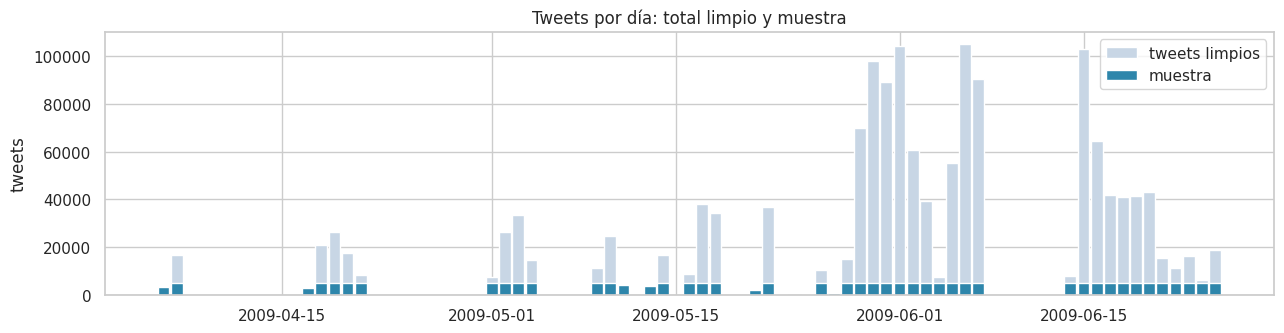

In [8]:
por_dia = pd.DataFrame({
    "limpios": df["dia"].value_counts(),
    "muestra": muestra["dia"].value_counts(),
}).sort_index()

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(por_dia.index, por_dia["limpios"], width=0.9, color="#c8d6e5", label="tweets limpios")
ax.bar(por_dia.index, por_dia["muestra"], width=0.9, color="#2e86ab", label="muestra")
ax.set(title="Tweets por día: total limpio y muestra", ylabel="tweets")
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
def resumen(d):
    return pd.Series({
        "tweets": len(d),
        "% abril": (d["dia"].dt.month == 4).mean() * 100,
        "% mayo": (d["dia"].dt.month == 5).mean() * 100,
        "% junio": (d["dia"].dt.month == 6).mean() * 100,
        "% positivos": (d["polaridad"] == 4).mean() * 100,
        "palabras (mediana)": d["texto_limpio"].str.split().str.len().median(),
    })

pd.DataFrame({"limpios": resumen(df), "muestra": resumen(muestra)}).round(1)

,limpios,muestra
tweets,1512388.0,217133.0
% abril,6.3,14.4
% mayo,36.0,41.9
% junio,57.7,43.8
% positivos,49.4,46.4
palabras (mediana),12.0,12.0


- Abril pasa de ~6% a ~14% y junio de ~58% a ~44%: el peso de cada día queda más parejo.
- La polaridad cambia un poco porque los últimos días solo tienen negativos (01). No afecta: la polaridad no se usa para los tópicos.
- Dentro de cada día la muestra es aleatoria, así que **la proporción de cada tema por día se conserva**. Es lo que se usa para buscar picos.

## 4. Embeddings

- Modelo: **`all-MiniLM-L6-v2`** (sentence-transformers). Convierte cada tweet en un vector de 384 números, de forma que tweets con significado parecido quedan cerca.
- Por qué este modelo: entrenado para similitud de oraciones en inglés, es liviano (6 capas) y es el que BERTopic usa por defecto para inglés.
- Los vectores se **normalizan** (largo 1): así el producto punto entre dos tweets es directamente su **similitud coseno**.
- Se calculan una vez y se guardan. BERTopic, KeyBERT y el clustering reutilizan los mismos vectores.

In [10]:
textos = muestra["texto_limpio"].tolist()

if utils.FILE_EMBEDDINGS.exists() and not RECALCULAR:
    emb = utils.cargar_embeddings(len(muestra))
    print("Embeddings cargados de", utils.FILE_EMBEDDINGS.name)
else:
    modelo = SentenceTransformer(utils.MODELO_EMBEDDINGS, device="cpu")
    inicio = time.time()
    emb = modelo.encode(textos, batch_size=BATCH_SIZE, normalize_embeddings=True,
                        show_progress_bar=False).astype(np.float32)
    minutos = (time.time() - inicio) / 60
    print(f"Embeddings calculados en {minutos:.1f} min ({len(textos) / (minutos * 60):.0f} tweets/s)")
    np.save(utils.FILE_EMBEDDINGS, emb)

print("Forma:", emb.shape, "| largo de los vectores:", np.linalg.norm(emb[:5], axis=1).round(3))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embeddings calculados en 13.3 min (272 tweets/s)
Forma: (217133, 384) | largo de los vectores: [1. 1. 1. 1. 1.]


**Control:** los vecinos más cercanos por similitud coseno de algunos tweets. Si los embeddings funcionan, deberían hablar de lo mismo aunque usen otras palabras.

In [11]:
def vecinos(i, k=5):
    sim = emb @ emb[i]                       # coseno: los vectores tienen largo 1
    top = np.argsort(-sim)[1:k + 1]
    return pd.DataFrame({"similitud": sim[top].round(3), "tweet": muestra["texto_limpio"].iloc[top].values})

for patron in ["farrah", "swine flu", "air france"]:
    i = muestra.index[muestra["texto_limpio"].str.lower().str.contains(patron)][0]
    print(f"\nTweet: {muestra['texto_limpio'].iloc[i]}")
    display(vecinos(i))


Tweet: Tune in for Farrah's Story Fri 9/8c on nbc. Pray that she stays alive long enough to watch it air Cancer sucks !!!!


,similitud,tweet
0,0.702,I'm really sad about Farrah I HATE cancer! I wish we could find something to BEAT that disease!
1,0.675,RIP Farrah Fawcett ... thoughts and prayers for her family and friends
2,0.672,RIP Farrah...u will be missed
3,0.671,"Can't believe that Farrah is on the verge of passing away. Never thought she'd die in this way, it's not fair"
4,0.669,"Heading to bed. Hope Farrah Fawcett isn't in any pain, this is such a tragedy. Cancer sucks."



Tweet: swine flu attacks HK so i can't go screw you swines!


,similitud,tweet
0,0.767,swine flu in HK. getting too close to home.
1,0.673,The swine flu is almost here ! We are going to die
2,0.673,Come on y'all - let's beat swine flu! TINK!
3,0.657,hopefully not swine flu!
4,0.655,"you gave me your swine flu, godammit."



Tweet: Been waiting in all day for Air France to return my case


,similitud,tweet
0,0.625,"air france? oh man, another tragedy to worry about"
1,0.610,Air France ... so tragic
2,0.610,"I would still use air france, is just like after the american airlines 911 case. my prayers go out to all the affected families"
3,0.598,Air France still missing.
4,0.591,sad for what happened with Air France here in Brazil


## 5. Guardar

In [12]:
columnas = ["id", "fecha_pdt", "dia", "usuario", "polaridad", "texto", "texto_limpio"]
muestra[columnas].to_csv(utils.FILE_MUESTRA, index=False)

for f in [utils.FILE_MUESTRA, utils.FILE_EMBEDDINGS]:
    print(f"{f.name:<20} {f.stat().st_size / 1e6:>7.1f} MB")

muestra.csv.gz          13.5 MB
embeddings.npy         333.5 MB


## 6. Resumen

| Paso | Resultado |
| --- | --- |
| Tweets de partida | 1.600.000 |
| Después de limpiar, deduplicar y filtrar | ~1,51 M |
| Muestra (hasta 5.000 por día, 48 días) | ~217 mil |
| Embeddings | 384 dimensiones, normalizados (`all-MiniLM-L6-v2`) |

- `muestra.csv.gz` se sube al repo. `embeddings.npy` no (~330 MB): se regenera con esta notebook.
- Las stopwords **no** se quitaron del texto: se quitan en el vectorizador de cada modelo, con la misma lista (`utils.STOPWORDS`).